# Testutvärdering och analys

Denna notebook genomför projektets slutliga utvärdering på den tidigare orörda testdatan samt demonstrerar hur huvudmodellen fattar beslut och förklaras med SHAP.

## 1. Modellval och förberedelser
### Valideringsresultat
Innan utvärdering på testdata genomfördes låstes projektets slutmodell baserat på valideringsresultaten (tidsbaserad split 2016-07-01):

| Modell | Precision@20% | Recall@20% | F1-score | PR-AUC | Korrekt flaggade (av 2329) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline (lead_time)** | 54,36% | 30,83% | 39,34% | 0,5057 | 1 266 |
| **Logistic Regression (utan deposit_type)** | 60,20% | 34,14% | 43,57% | 0,5772 | 1 402 |
| **Random Forest (utan deposit_type)** | **64,75%** | **36,72%** | **46,86%** | **0,5913** | **1 508** |

### Val av slutmodell
- **Modell:** Random Forest Classifier (`n_estimators=100`, `max_depth=15`, `min_samples_leaf=10`, `random_state=42`).
- **Feature-set:** Exkluderar `deposit_type` på grund av risk för dataläckage och `distribution_channel` som överlappar med `market_segment`.
- **Träning för test:** Modellen tränas om på `train_full` (alla ankomster före 2016-10-01) och utvärderas en enda gång på `test` (bokningar gjorda oktober–december 2016).

### Förberedelser

In [1]:
import os

# Sätt arbetskatalog till projektroten om notebooken körs från notebooks/
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

print("Arbetskatalog:", os.getcwd())


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from src.data_split import load_cleaned_data, get_splits
from src.preprocessing import split_features_target, build_preprocessor
from src.logistic_regression import train_logistic_regression
from src.random_forest import train_random_forest
from src.prediction import predict_probabilities
from src.evaluation import (
    evaluate_model,
    evaluate_top_share,
    flag_top_share,
    plot_booking_shap_waterfall,
    clean_feature_names,
    plot_confusion_matrix,
    plot_pr_curve
)
from src.experiment_logger import save_plot, log_experiment
from src.model_io import save_model_artifacts

Arbetskatalog: c:\Users\josef\Desktop\data-science-group-project


### Datainläsning och tidsuppdelning

In [2]:
df = load_cleaned_data()
splits = get_splits(df)

train_full = splits["train_full"]
test = splits["test"]

print(f"Träningsdata (train_full): {train_full.shape} (avbokningsandel: {train_full['is_canceled'].mean():.2%})")
print(f"Testdata (test):           {test.shape} (avbokningsandel: {test['is_canceled'].mean():.2%})")

2026-10-27 17:49:21 [INFO] src.data_split: Läser in städad data från data\processed\hotel_bookings_cleaned.csv
2026-10-27 17:49:21 [INFO] src.data_cleaning: Validerar städad data med Pandera...
2026-10-27 17:49:21 [INFO] src.data_cleaning: Datavalidering godkänd utan anmärkningar.
2026-10-27 17:49:21 [INFO] src.data_split: Split vid 2016-07-01: 40414 träning (avbokade 0.308), 11643 utvärdering (avbokade 0.353)
2026-10-27 17:49:21 [INFO] src.data_split: Split vid 2016-10-01: 55393 träning (avbokade 0.321), 14879 utvärdering (avbokade 0.396)
Träningsdata (train_full): (55393, 34) (avbokningsandel: 32.13%)
Testdata (test):           (14879, 34) (avbokningsandel: 39.60%)


## 2. Preprocessing och förberedelse av testdata

Preprocessorn anpassas (`fit_transform`) uteslutande på träningsmängden (`train_full`, 55 393 rader) för att förhindra dataläckage, och appliceras sedan (`transform`) på testmängden (`test`, 14 879 rader).

Totalt expanderas datamängden till 127 kolumner efter One-Hot Encoding och frekvensfiltrering av agenter.

In [3]:
# Separera features och målvariabel för huvudmodellen (utan deposit_type)
X_train_full, y_train_full = split_features_target(train_full, include_deposit_type=False)
X_test, y_test = split_features_target(test, include_deposit_type=False)

# Bygg och anpassa preprocessorn endast på träningsdata
preprocessor = build_preprocessor(include_deposit_type=False)
X_train_processed = preprocessor.fit_transform(X_train_full)
X_test_processed = preprocessor.transform(X_test)

print("Transformerad träning:", X_train_processed.shape)
print("Transformerad test:   ", X_test_processed.shape)

Transformerad träning: (55393, 127)
Transformerad test:    (14879, 127)


## 3. Modellträning och riskprediktion

Vi tränar om projektets tre jämförda modeller på hela den historiska träningsdatan och genererar predicerade avbokningssannolikheter för testbokningarna.

In [4]:
# 1. Baseline: riskpoäng är lead_time direkt på test
scores_baseline = test["lead_time"]

# 2. Logistic Regression
lr_model = train_logistic_regression(X_train_processed, y_train_full)
probas_lr = predict_probabilities(lr_model, X_test_processed)

# 3. Random Forest (låsta hyperparametrar för huvudmodellen)
rf_model = train_random_forest(
    X_train_processed,
    y_train_full,
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=10,
    random_state=42
)
probas_rf = predict_probabilities(rf_model, X_test_processed)

# Spara slutmodellen och den anpassade preprocessorn till outputs/models
save_model_artifacts(rf_model, preprocessor)

print("Modeller tränade, artefakter sparade och förutsägelser klara på testdata!")

2026-10-27 17:49:22 [INFO] src.model_io: Sparar modellartefakter till outputs\models...
2026-10-27 17:49:22 [INFO] src.model_io: Modell (final_model_rf.joblib) och preprocessor (preprocessor.joblib) sparades framgångsrikt.
Modeller tränade, artefakter sparade och förutsägelser klara på testdata!


## 4. Utvärdering på testdata vid Top 20 % flaggning

Hotellverksamheten har kapacitet att hantera proaktiva åtgärder för de 20 % mest riskfyllda bokningarna (2 976 av totalt 14 879 bokningar). 

Här utvärderas hur väl modellerna rangordnar testdatan och hur många faktiska avbokningar som fångas upp vid denna operativa gräns.

In [5]:
# Utvärdera alla modeller vid 20 % flaggning på testdata
metrics_baseline = evaluate_top_share(y_test, scores_baseline, share=0.20)
metrics_lr = evaluate_top_share(y_test, probas_lr, share=0.20)
metrics_rf = evaluate_top_share(y_test, probas_rf, share=0.20)

# Slumpmässig flaggning beräknas: precision = andelen avbokade, recall = 20 %
base_rate = y_test.mean()
n_flagged = metrics_rf["antal_flaggade"]

rows = [{
    "Modell": "Slumpmässig flaggning (beräknad)",
    "Precision@20%": f"{base_rate:.2%}",
    "Recall@20%": f"{0.20:.2%}",
    "F1-score": f"{2 * base_rate * 0.20 / (base_rate + 0.20):.2%}",
    "PR-AUC": f"{base_rate:.4f}",
    "Korrekt flaggade": round(n_flagged * base_rate),
}]

for name, m in [("Baseline (lead_time)", metrics_baseline),
                ("Logistic Regression", metrics_lr),
                ("Random Forest", metrics_rf)]:
    rows.append({
        "Modell": name,
        "Precision@20%": f"{m['precision']:.2%}",
        "Recall@20%": f"{m['recall']:.2%}",
        "F1-score": f"{m['f1_score']:.2%}",
        "PR-AUC": f"{m['pr_auc']:.4f}",
        "Korrekt flaggade": m["korrekt_flaggade"],
    })

results_summary = pd.DataFrame(rows)
display(results_summary)

,Modell,Precision@20%,Recall@20%,F1-score,PR-AUC,Korrekt flaggade
0,Slumpmässig flaggning (beräknad),39.60%,20.00%,26.58%,0.3960,1178
1,Baseline (lead_time),50.81%,25.66%,34.10%,0.5043,1512
2,Logistic Regression,80.68%,40.75%,54.15%,0.7547,2401
3,Random Forest,81.75%,41.29%,54.87%,0.7750,2433


2026-10-27 17:49:22 [INFO] src.experiment_logger: Figur sparad: outputs\figures\test_pr_curves.png


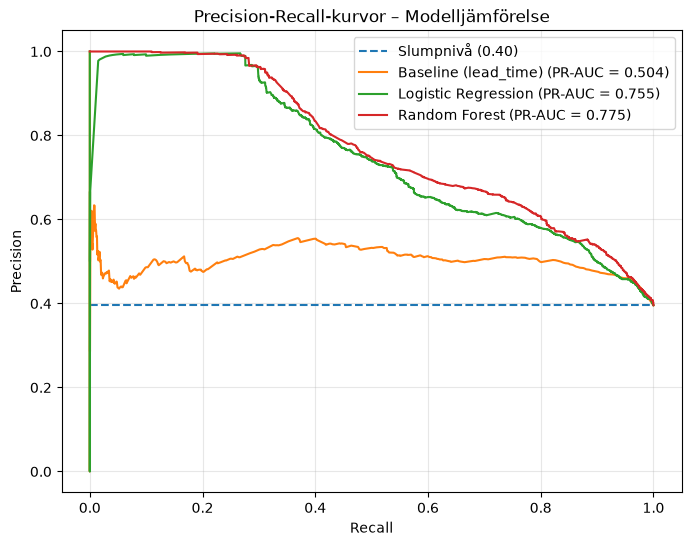

In [6]:
# PR-kurvor på testdatan
test_predictions = {
    "Baseline (lead_time)": scores_baseline,
    "Logistic Regression": probas_lr,
    "Random Forest": probas_rf
}

plot_pr_curve(y_test, test_predictions)
save_plot("test_pr_curves.png")
plt.show()

### Resultatanalys på testdata
* **Random Forest** är projektets starkaste modell med **81,75 % precision** och **41,29 % recall** vid 20 % flaggning (2 433 korrekt flaggade avbokningar av 2 976).
* **Jämförelse med baseline:** Baseline (`lead_time`) når endast **50,81 %** precision och fångar 1 512 avbokningar. Random Forest identifierar alltså **921 fler avbokningar** vid samma arbetsinsats.
* **PR-AUC:** Random Forest uppnår **0,7750** jämfört med **0,7547** för Logistic Regression och **0,5043** för baseline. Modellen rangordnar alltså bokningarna bättre även om hotellet väljer att flagga fler eller färre än 20 %.

**Jämförelse med validering:** Resultaten är klart högre än på valideringsdatan (64,75 % precision för Random Forest). Skillnaden undersöks nedan.

### Ej återbetalningsbara bokningar (Non Refund)

I EDA:n konstaterades att ej återbetalningsbara bokningar avbokas i 99 % av fallen och beter sig som gruppblock från resebyråer snarare än som enskilda bokningar. Modellerna använder inte `deposit_type`, men kan ändå känna igen bokningarna via andra variabler, till exempel `agent`, `lead_time` och `market_segment`.

Här undersöks hur stor andel ej återbetalningsbara bokningar det finns i varje delmängd, hur stor del av de flaggade bokningarna de utgör, och hur modellerna presterar utan dem. Bland de återstående bokningarna flaggas på nytt 20 %. `deposit_type` används bara för att dela upp resultatet i efterhand, inte som indata till modellerna.

In [7]:
# Andel ej återbetalningsbara bokningar per delmängd
for name in ["train_full", "val", "test"]:
    share = (splits[name]["deposit_type"] == "Non Refund").mean()
    print(f"Andel Non Refund i {name}: {share:.2%}")

non_refund = (test["deposit_type"] == "Non Refund").to_numpy()
y_test_arr = np.asarray(y_test)

print(f"Andel avbokade utan Non Refund: {y_test_arr[~non_refund].mean():.2%} "
      "(motsvarar precision vid slumpmässig flaggning)")

rows = []
for name, scores in test_predictions.items():
    scores = np.asarray(scores)
    flagged = flag_top_share(scores, share=0.20).astype(bool)

    # Flagga på nytt 20 % bland bokningarna som inte är Non Refund
    m = evaluate_top_share(y_test_arr[~non_refund], scores[~non_refund], share=0.20)

    rows.append({
        "Modell": name,
        "Andel Non Refund bland flaggade": f"{non_refund[flagged].mean():.2%}",
        "Precision@20% utan Non Refund": f"{m['precision']:.2%}",
        "Recall@20% utan Non Refund": f"{m['recall']:.2%}",
        "PR-AUC utan Non Refund": f"{m['pr_auc']:.4f}",
    })

display(pd.DataFrame(rows))

Andel Non Refund i train_full: 10.90%
Andel Non Refund i val: 1.95%
Andel Non Refund i test: 13.85%
Andel avbokade utan Non Refund: 29.90% (motsvarar precision vid slumpmässig flaggning)


,Modell,Andel Non Refund bland flaggade,Precision@20% utan Non Refund,Recall@20% utan Non Refund,PR-AUC utan Non Refund
0,Baseline (lead_time),17.04%,41.15%,27.52%,0.3909
1,Logistic Regression,62.30%,50.78%,33.97%,0.4413
2,Random Forest,62.97%,52.15%,34.88%,0.4713


### Analys - ej återbetalningsbara bokningar

Andelen ej återbetalningsbara bokningar är 10,9 % i träningsdatan (`train_full`), 1,9 % i valideringsdatan och 13,8 % i testdatan. Valideringsdatan innehåller alltså nästan inga sådana bokningar, medan testdatan innehåller fler än träningsdatan.

63 % av de bokningar som Random Forest flaggar är ej återbetalningsbara, och 62 % för logistisk regression. Baselinen, som bara använder `lead_time`, flaggar 17 % sådana bokningar.

Utan dem sjunker precisionen för Random Forest från 81,75 % till 52,15 % och PR-AUC från 0,775 till 0,471. Andelen avbokade bland de återstående bokningarna är 29,9 %, vilket motsvarar precisionen vid slumpmässig flaggning. Random Forest (52,15 %) och logistisk regression (50,78 %) slår fortfarande baselinen (41,15 %), och ordningen mellan modellerna är densamma.

Det höga testresultatet beror alltså till stor del på att testdatan innehåller många ej återbetalningsbara gruppbokningar, som är lätta att känna igen och nästan alltid avbokas. För bokningar som inte är ej återbetalningsbara har Random Forest en precision på 52 %, mot 29,9 % vid slumpmässig flaggning.

## 5. Modelljämförelse – City Hotel vs. Resort Hotel

### Syfte

Undersöka om Baseline, Logistic Regression och Random Forest presterar olika för City Hotel och Resort Hotel när de identifierar bokningar med hög risk för avbokning.

### Metod

Jämförelsen görs på projektets testdata med de redan tränade modellerna, utan ny träning. De 20 % mest riskfyllda bokningarna flaggas för varje modell, oavsett hotelltyp. Därefter jämförs precision och recall separat för respektive hotelltyp.

### Förberedelse av jämförelsen

Samlar hotelltyp, verkliga avbokningar och modellernas riskpoäng i en gemensam DataFrame.

In [8]:
# Samla testdata och modellernas riskpoäng
hotel_comparison = pd.DataFrame({
    "hotel": test["hotel"],
    "is_canceled": y_test,
    "baseline_score": scores_baseline,
    "lr_score": probas_lr,
    "rf_score": probas_rf,
})

hotel_comparison.head()

,hotel,is_canceled,baseline_score,lr_score,rf_score
7067,Resort Hotel,0,2,0.055435,0.102969
7127,Resort Hotel,1,1,0.046946,0.109107
7129,Resort Hotel,1,5,0.047827,0.110463
7130,Resort Hotel,1,6,0.214870,0.136827
7146,Resort Hotel,1,2,0.101167,0.122482


### Identifiera riskfyllda bokningar

För varje modell flaggar vi de 20 % bokningar som har högst riskpoäng, oavsett hotelltyp.

In [9]:
# Flagga de 20 % med högst risk för varje modell
hotel_comparison["baseline_flag"] = flag_top_share(
    hotel_comparison["baseline_score"], share=0.20
)

hotel_comparison["lr_flag"] = flag_top_share(
    hotel_comparison["lr_score"], share=0.20
)

hotel_comparison["rf_flag"] = flag_top_share(
    hotel_comparison["rf_score"], share=0.20
)

# Kontrollera antalet flaggade bokningar
hotel_comparison[
    ["baseline_flag", "lr_flag", "rf_flag"]
].sum()

baseline_flag    2976
lr_flag          2976
rf_flag          2976
dtype: int64

### Utvärdering per hotelltyp

Beräknar precision, recall och andelen flaggade bokningar för varje modell, uppdelat på City Hotel och Resort Hotel.

In [10]:
results = []

for model, flag_col in {
    "Baseline": "baseline_flag",
    "Logistic Regression": "lr_flag",
    "Random Forest": "rf_flag"
}.items():

    for hotel, group in hotel_comparison.groupby("hotel"):

        metrics = evaluate_model(
            group["is_canceled"],
            group[flag_col]
        )

        results.append({
            "Model": model,
            "Hotel": hotel,
            "Precision (%)": round(metrics["Precision"] * 100, 2),
            "Recall (%)": round(metrics["Recall"] * 100, 2),
            "Flagged (%)": round(group[flag_col].mean() * 100, 2)
        })

hotel_results = pd.DataFrame(results)

hotel_results

,Model,Hotel,Precision (%),Recall (%),Flagged (%)
0,Baseline,City Hotel,55.75,24.05,19.97
1,Baseline,Resort Hotel,40.11,32.14,20.06
2,Logistic Regression,City Hotel,82.34,46.24,26.00
3,Logistic Regression,Resort Hotel,67.18,18.67,6.96
4,Random Forest,City Hotel,85.22,44.23,24.03
5,Random Forest,Resort Hotel,65.65,29.50,11.25


### Visualisering av modellernas resultat

Stapeldiagrammen visar precision och recall för respektive modell och hotelltyp för att underlätta jämförelsen.

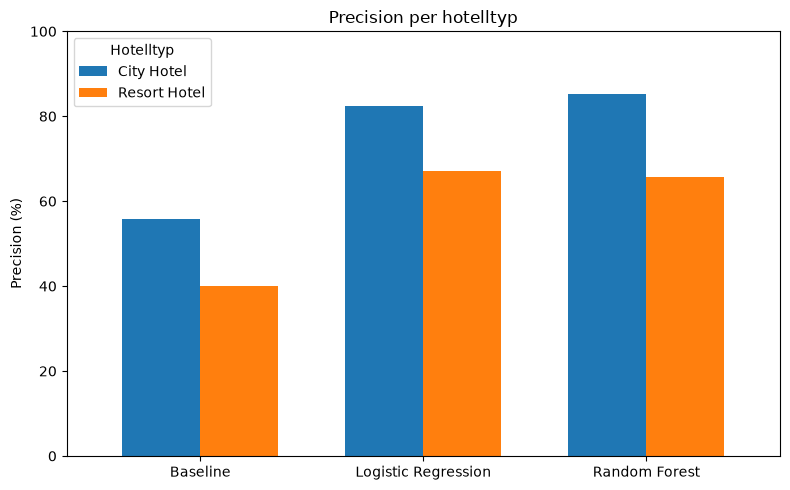

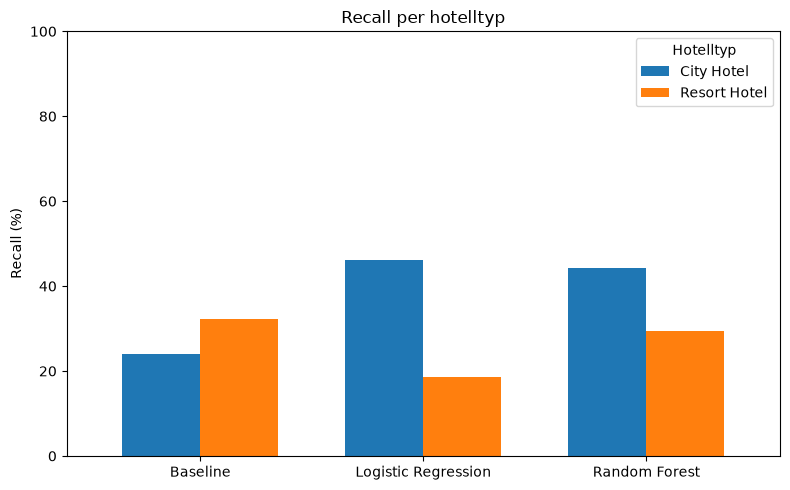

In [11]:
metrics = ["Precision (%)", "Recall (%)"]
titles = ["Precision per hotelltyp", "Recall per hotelltyp"]

for metric, title in zip(metrics, titles):

    ax = hotel_results.pivot(
        index="Model",
        columns="Hotel",
        values=metric
    ).plot(
        kind="bar",
        figsize=(8, 5),
        width=0.7
    )

    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.set_xlabel("")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Hotelltyp")

    plt.tight_layout()
    plt.show()

### Bokningar och avbokningar per hotelltyp

Beräknar antal bokningar, andelen avbokade och andelen ej återbetalningsbara bokningar för City Hotel och Resort Hotel.

In [12]:
# Antal bokningar, andel avbokade och andel Non Refund per hotell
hotel_overview = test.groupby("hotel").agg(
    antal_bokningar=("is_canceled", "size"),
    andel_avbokade=("is_canceled", "mean"),
)
hotel_overview["andel_non_refund"] = (
    (test["deposit_type"] == "Non Refund").groupby(test["hotel"]).mean()
)

display(hotel_overview.style.format({
    "andel_avbokade": "{:.2%}",
    "andel_non_refund": "{:.2%}",
}))

,antal_bokningar,andel_avbokade,andel_non_refund
hotel,,,
City Hotel,10193,46.30%,19.15%
Resort Hotel,4686,25.03%,2.30%


### Analys – City Hotel vs. Resort Hotel

City Hotel har 10 193 bokningar i testdatan, med 46,30 % avbokningar och 19,15 % ej återbetalningsbara bokningar. Resort Hotel har 4 686 bokningar, med 25,03 % avbokningar och 2,30 % ej återbetalningsbara.

Random Forest flaggar 24,03 % av bokningarna på City Hotel och 11,25 % på Resort Hotel, med en precision på 85,22 % respektive 65,65 %. Precisionen är högre för City Hotel, men där är också andelen avbokade högre (46,30 % mot 25,03 %), och nästan alla ej återbetalningsbara bokningar finns där (19,15 % mot 2,30 %). Jämfört med andelen avbokade ligger modellen längre över slumpmässig flaggning för Resort Hotel (cirka 2,6 gånger) än för City Hotel (cirka 1,8 gånger).

**Sammanfattningsvis beror den högre precisionen för City Hotel främst på att avbokningar och gruppbokningar är vanligare där, inte på att modellen är bättre på att skilja ut riskbokningar.** Modellen flaggar fler bokningar på City Hotel eftersom risken är högre där. Resultatet för ett hotell beror alltså på hur bokningarna där ser ut, och modellen bör utvärderas separat innan den används på ett nytt hotell.

## 6. Förväxlingsmatris för Random Forest

Förväxlingsmatrisen illustrerar det praktiska utfallet för hotellpersonalen.

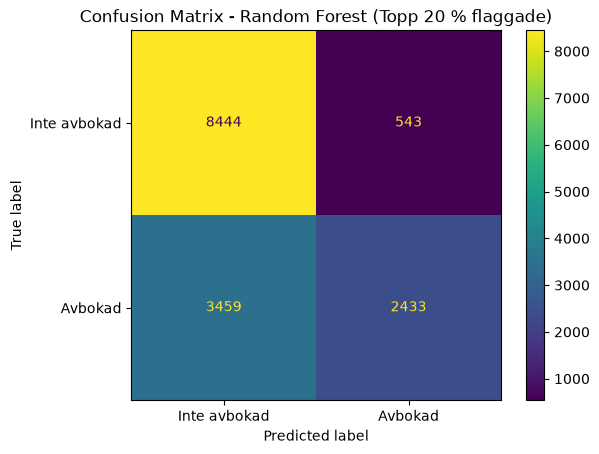

In [13]:
# 1. Identifiera och flagga de 20 % bokningarna med högst predicerad risk
y_pred_rf = pd.Series(flag_top_share(probas_rf, share=0.20), index=test.index)
y_true = pd.Series(y_test, index=test.index)

# 2. Förväxlingsmatris för Random Forest vid 20 % flaggning
fig = plot_confusion_matrix(y_true, y_pred_rf)
plt.title("Confusion Matrix - Random Forest (Topp 20 % flaggade)")
plt.show()

### Analys – förväxlingsmatris

* **True Positives (2 433 st):** Faktiska avbokningar som modellen korrekt identifierat för proaktiva åtgärder.
* **False Positives (543 st):** Bokningar som flaggats i onödan, 18 % av de flaggade totalt.
* **Ej flaggade (11 903 st):** Bokningar som lämnas utan åtgärd enligt 20 %-regeln. Av dessa är det **3 459 falskt negativa** och 8 444 korrekt ej flaggade. 

Eftersom testdatan har 5 892 avbokningar men bara 2 976 bokningar flaggas, kan även en perfekt modell som mest hitta 50,5 % av avbokningarna vid 20 %-gränsen. Random Forest hittar 41,3 %.

En stor del av de korrekt flaggade är ej återbetalningsbara gruppbokningar (se avsnitt 4). För vanliga enskilda bokningar är ungefär hälften av de flaggade falsklarm, inte under 1 av 5.

## 7. Förklaring av modellens bedömningar med SHAP

För att skapa transparens och förståelse för verksamheten visualiseras modellens beslutsfattande med SHAP (TreeExplainer). 

**Så läses vattenfallsdiagrammen (nedifrån och upp):**
* **Baslinjen $E[f(X)] = 0,321$:** Den genomsnittliga avbokningsrisken i träningsdatan (32,1 %).
* **Röda pilar ($+$):** Egenskaper som driver upp risken för avbokning.
* **Blå pilar ($-$):** Egenskaper som sänker risken för avbokning.
* **Slutvärdet $f(x)$:** Modellens slutgiltiga beräknade sannolikhet för den specifika bokningen.

Vi analyserar fyra representativa fall: extremt hög risk, bokningar precis över och under tröskelvärdet, samt extremt låg risk.

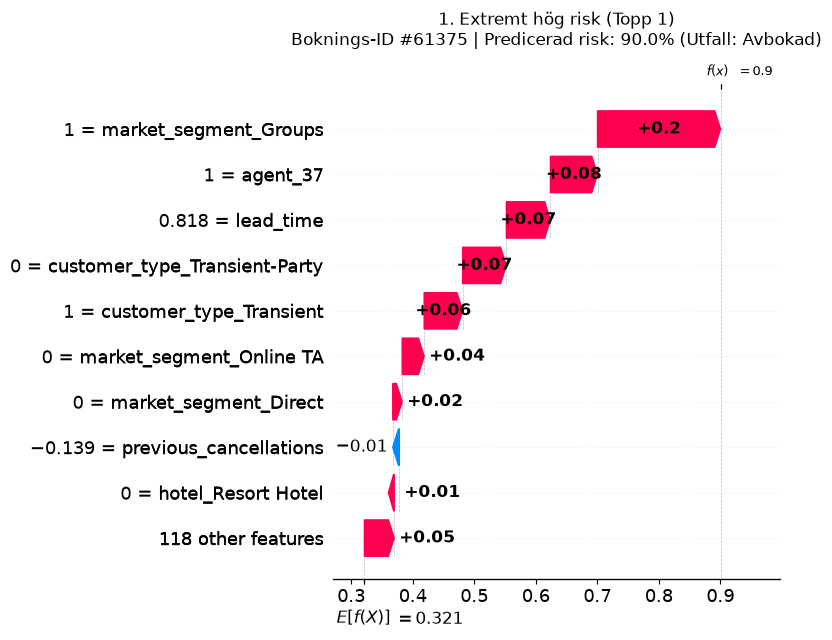

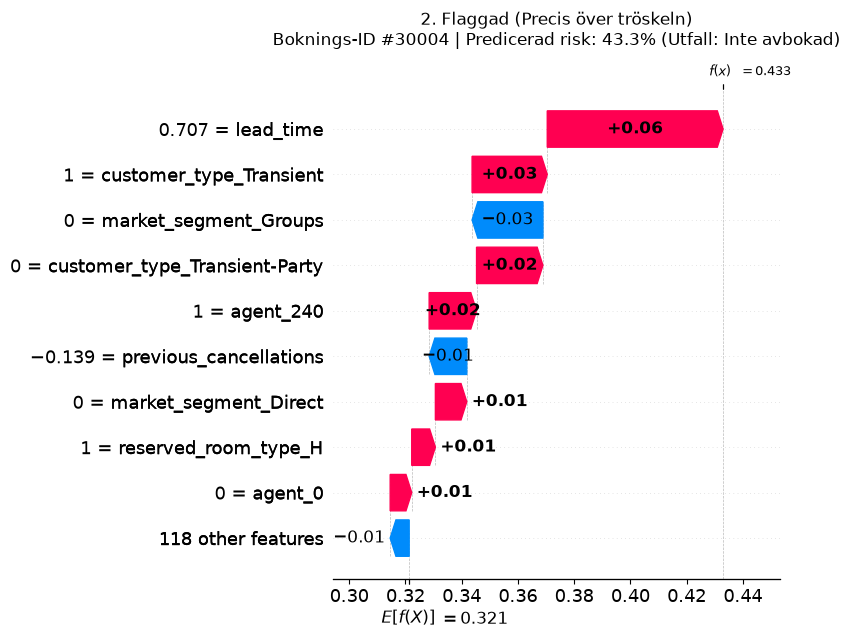

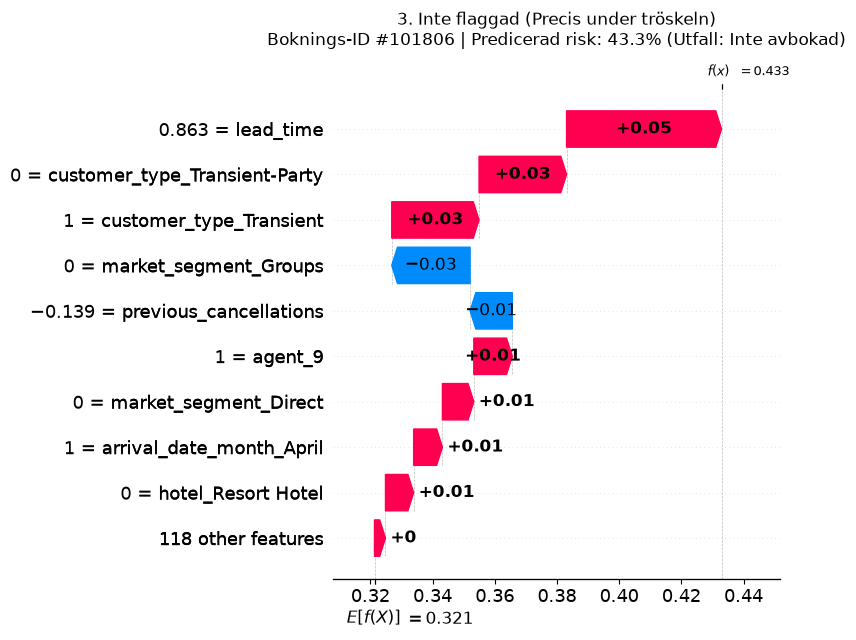

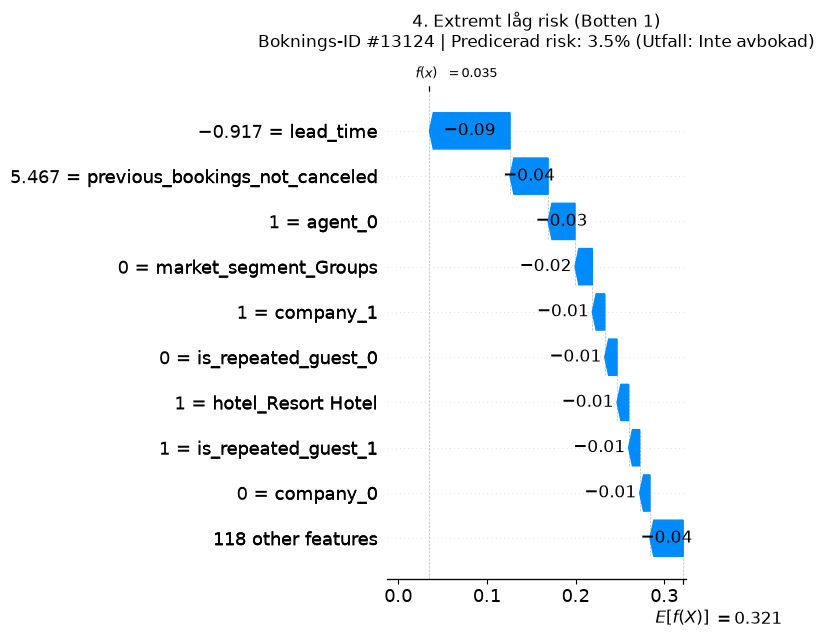

In [14]:
# 1. Rangordna testmängden baserat på befintliga prediktioner (blixtsnabbt)
test_ranking = pd.DataFrame({
    "pred_prob": probas_rf,
    "is_canceled": y_test.values
}, index=test.index).sort_values(by="pred_prob", ascending=False)

n_flagged = int(np.ceil(len(test_ranking) * 0.20))
prob_cutoff = test_ranking.iloc[n_flagged - 1]["pred_prob"]

strictly_above = test_ranking[test_ranking["pred_prob"] > prob_cutoff]
idx_above = strictly_above.index[-1] if len(strictly_above) > 0 else test_ranking.index[n_flagged - 1]
idx_below = test_ranking[test_ranking["pred_prob"] < prob_cutoff].index[0]

cases = [
    ("1. Extremt hög risk (Topp 1)", test_ranking.index[0]),
    ("2. Flaggad (Precis över tröskeln)", idx_above),
    ("3. Inte flaggad (Precis under tröskeln)", idx_below),
    ("4. Extremt låg risk (Botten 1)", test_ranking.index[-1]),
]

# 2. Rita enbart de 4 fallen direkt med din hjälpfunktion (tar ca 0,5 sek totalt)
for title, idx in cases:
    prob = test_ranking.loc[idx, "pred_prob"]
    actual = "Avbokad" if test_ranking.loc[idx, "is_canceled"] == 1 else "Inte avbokad"
    full_title = f"{title}\nBoknings-ID #{idx} | Predicerad risk: {prob:.1%} (Utfall: {actual})"
    
    # Plocka ut enbart denna specifika rad ur rådata (precis som i demon)
    single_booking = X_test.loc[[idx]]
    
    plot_booking_shap_waterfall(
        rf_model,
        preprocessor,
        single_booking,
        title=full_title,
        max_display=10
    )

### Analys – SHAP-förklaringar

Värdena för numeriska variabler, som `lead_time` och `previous_bookings_not_canceled`, är standardiserade. Ett positivt värde betyder högre än genomsnittet i träningsdatan och ett negativt lägre. För kategoriska variabler betyder 1 att bokningen tillhör kategorin och 0 att den inte gör det.

**1. Extremt hög risk (90 %, avbokad).** Det som drar upp risken mest är att bokningen tillhör marknadssegmentet `Groups` (+0,20), är gjord via agent 37 (+0,08) och har lång ledtid (156 dagar, +0,07). Bokningen är ej återbetalningsbar och gäller City Hotel. Modellen använder inte `deposit_type`, men har lärt sig känna igen den här typen av gruppbokningar från resebyråer via segment, agent och ledtid, vilket stämmer med resultatet i avsnitt 4.

**2–3. Precis över och under tröskeln (båda 43,29 %, inte avbokade).** Bokningarna har nästan samma sannolikhet och liknande förklaringar: lång ledtid och kundtypen `Transient` drar upp risken, medan att de inte tillhör `Groups` drar ned den. Den ena flaggas och den andra inte, trots att skillnaden är försumbar. Gränsen vid 20 % är alltså ett praktiskt val av hur många bokningar hotellet hinner följa upp, inte en tydlig skiljelinje mellan riskbokningar och övriga. Ingen av dem avbokades, vilket visar att bokningar nära gränsen ofta inte avbokas.

**4. Extremt låg risk (3,5 %, inte avbokad).** Kort ledtid sänker risken mest (−0,09). Därefter följer många tidigare genomförda bokningar (−0,04), att bokningen inte är gjord via en resebyrå (agent 0), att den är kopplad till ett företag och att gästen har bokat tidigare. Profilen motsvarar en återkommande företagsgäst.

SHAP visar hur modellen använder variablerna, inte vad som orsakar avbokningar. Förklaringarna stämmer med EDA:n, där lång ledtid och segmentet `Groups` hade hög avbokningsandel och återkommande gäster låg.

### Experimentloggning

Sparar testresultaten för de tre modellerna i experimentloggen. Loggningen är avstängd som standard.

In [15]:
# Ändra till True vid den slutliga körningen
SAVE_EXPERIMENT = False

if SAVE_EXPERIMENT:
    for name, feature_set, m in [
        ("Baseline", "lead_time", metrics_baseline),
        ("Logistic Regression", "utan deposit_type", metrics_lr),
        ("Random Forest", "utan deposit_type", metrics_rf),
    ]:
        log_experiment(model_name=name, feature_set=feature_set, metrics=m,
                       dataset="test", notes="Tränad på train_full (55 393 rader). Top 20 %.")
    print("Testresultaten har loggats.")
else:
    print("Testresultaten har inte loggats.")

Testresultaten har inte loggats.


## 8. Slutsats och rekommendation

* **Modellbeslut:** Random Forest (`max_depth=15`, `min_samples_leaf=10`) utan `deposit_type` och `distribution_channel` valdes på valideringsdatan och gav högst precision och recall även på testdatan vid 20 % flaggning. Vi har försökt minska risken för dataläckage genom vårt val av variabler och vår tidsuppdelning, men kan inte helt utesluta att det förekommer.
* **Jämfört med regeln:** Vid samma antal flaggade bokningar hittar Random Forest 2 433 avbokningar, mot 1 512 för regeln om bokningar långt i förväg. Modellen är bättre än regeln även när de ej återbetalningsbara bokningarna tas bort (52 % mot 41 % precision).
* **Operativ nytta:** Totalt avbokas drygt 8 av 10 flaggade bokningar, men det beror till stor del på gruppbokningar från resebyråer. För vanliga enskilda bokningar avbokas ungefär hälften av de flaggade. Modellen passar därför för riktade åtgärder, som påminnelser eller förfrågningar om bekräftelse, men inte för beslut om enskilda gäster utan mänsklig bedömning.
* **Individuellt beslutsstöd:** Med SHAP kan personalen se vilka faktorer, till exempel lång ledtid, specifika agenter eller marknadssegment, som ligger bakom en flaggning.